# S07 · Учим сеть узнавать рисунки

23 октября 2026. Выполняйте ячейки сверху вниз с чистого ядра. Полный пример с результатами.

## C01 · Инструменты

Будем хранить рисунки в числовых таблицах и обучать их преобразование. NumPy читает таблицы, matplotlib показывает рисунки и графики, PyTorch вычисляет производные и меняет параметры сети. Его число или таблица называются тензором. Path нужен для пути к файлу, train_test_split для отдельной проверки, nn для слоёв и потерь. Импортируйте эти инструменты. Выберите заранее один поток CPU и генератор PyTorch 7, чтобы повторять один запуск.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.model_selection import train_test_split
from torch import nn

torch.set_num_threads(1)
_ = torch.manual_seed(7)


## C02 · Рисунки с диска

Локальный NPZ хранит несколько числовых массивов в одном файле. Прочитайте data/quickdraw-cat-teapot.npz: images содержит 1200 строк по 784 пикселя, labels хранит известный ответ каждой строки, 0=кот, 1=чайник. Создайте имена ['кот','чайник']. Проверьте размеры через shape до обучения, чтобы не перепутать число рисунков и пикселей. [Источник и отбор](../../data/QUICKDRAW-README.md).

In [2]:
folder = Path.cwd()
if folder.name == "solutions":
    folder = folder.parent
if folder.name == "notebooks":
    folder = folder.parent
if folder.name != "starter":
    folder = folder / "starter"
data = np.load(folder / "data/quickdraw-cat-teapot.npz")
images = data["images"]
labels = data["labels"]
names = ["кот", "чайник"]
print(images.shape, labels.shape)


(1200, 784) (1200,)


## C03 · Человеческие рисунки

Сначала проверим, какие именно данные получили. Покажите строки 3,4,5 и 603,604,605: по три кота и чайника из файла, где сначала идут 600 котов. reshape(28,28) возвращает 784 пикселя в расположение картинки, не меняя их значения. Подпишите исходную метку, чтобы видеть, что сеть будет учиться предсказывать.

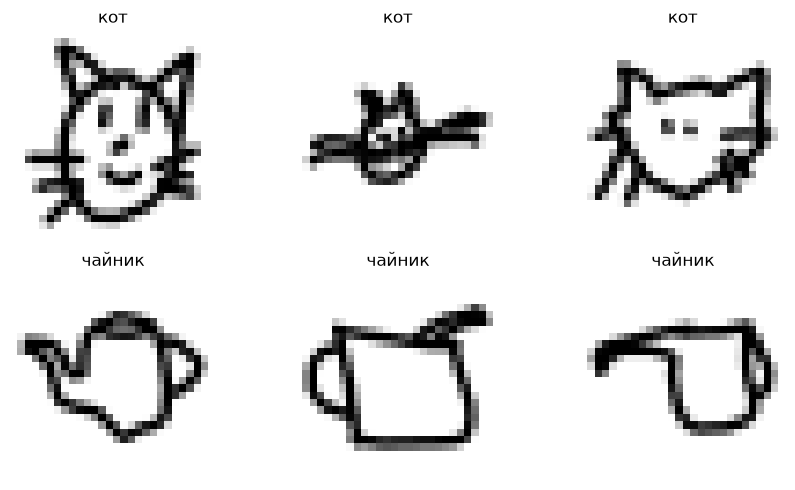

In [3]:
examples = [3, 4, 5, 603, 604, 605]
plt.figure(figsize=(9, 5))
for position, index in enumerate(examples):
    plt.subplot(2, 3, position + 1)
    plt.imshow(images[index].reshape(28, 28), cmap="gray_r")
    plt.title(names[labels[index]])
    plt.axis("off")
plt.tight_layout()
plt.show()


## C04 · Один градиент

Прежде чем доверить библиотеке тысячи производных, сверим одну с ручным ответом. ReLU нужна для нелинейного преобразования: без неё линейные слои сводятся к одному. Условие: w=1, h=ReLU(w)=max(0,w), z=h-1, y=1 (чайник). Сигмоида z=0 даёт p=0.5; логарифмическая потеря -ln(0.5). requires_grad=True просит сохранять операции для производной, backward вычисляет её, w.grad хранит результат. BCEWithLogitsLoss принимает z и считает сигмоиду внутри. Напишите пример целиком; ждём производную -0.5, сам вес пока не обновляем.

In [4]:
w = torch.tensor(1.0, requires_grad=True)
h = torch.relu(w)
z = h - 1
one_loss = nn.BCEWithLogitsLoss()(z, torch.tensor(1.0))
one_loss.backward()
print("loss =", round(one_loss.item(), 6))
print("gradient =", w.grad.item())


loss = 0.693147
gradient = -0.5


## C05 · Потеря есть, градиент равен нулю

Проверим, может ли ошибка быть большой, а производная веса нулевой. Создайте отдельный negative_w=-1 с requires_grad=True. Фиксированы вход 1, скрытое смещение 0, выходной вес 1, смещение -1, метка 1. ReLU отрицательной суммы возвращает 0 и имеет здесь производную 0. Посчитайте negative_h=ReLU(negative_w), negative_z=negative_h-1, BCEWithLogitsLoss и backward. Выведите потерю и производную; команды обновления веса в этом опыте нет.

In [5]:
negative_w = torch.tensor(-1.0, requires_grad=True)
negative_h = torch.relu(negative_w)
negative_z = negative_h - 1
negative_loss = nn.BCEWithLogitsLoss()(negative_z, torch.tensor(1.0))
negative_loss.backward()
print("negative loss =", round(negative_loss.item(), 6))
print("negative gradient =", negative_w.grad.item())


negative loss = 1.313262
negative gradient = 0.0


## C06 · Обучение и отдельная проверка

Чтобы входы имели удобный масштаб для выбранного шага, поделите интенсивности images на их максимальное значение шкалы 255: диапазон 0..255 станет 0..1. Для проверки на новых рисунках заранее спрячьте 1/3 из 1200, то есть 400; остальные 800 используйте для обучения. train_test_split должен переносить входы и метки вместе. stratify=labels сохраняет доли котов/чайников, random_state=7 фиксирует выбранное разбиение.

In [6]:
X = images / 255.0
X_train, X_test, y_train, y_test = train_test_split(
    X, labels, test_size=1 / 3, random_state=7, stratify=labels
)
print("train:", len(X_train), "test:", len(X_test))


train: 800 test: 400


## C07 · Таблицы для PyTorch

Слои PyTorch работают со своими числовыми таблицами, тензорами. Переведите X_train, X_test, y_train, y_test через torch.tensor в вещественный тип torch.float32, как у параметров слоёв по умолчанию. Один выход сети на рисунок требует одного столбца ответов: reshape(-1,1) задаёт столбец и автоматически определяет число строк. Покажите формы (800,784) и (800,1), чтобы проверить соответствие рисунков и меток.

In [7]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
print(X_train.shape, y_train.shape)


torch.Size([800, 784]) torch.Size([800, 1])


## C08 · Небольшая сеть

Соберите вычисления по порядку: Linear(784,16) строит 16 взвешенных сумм пикселей, ReLU оставляет положительные части и добавляет нелинейность, Linear(16,1) собирает их в один выход z. Отдельная сигмоида дала бы оценку чайника p. BCEWithLogitsLoss считает её внутри при сравнении с меткой. SGD обновляет веса и смещения по производным: новый параметр = старый - 0.5*производная. Число 16, шаг 0.5 и генератор 7 выбраны заранее. Напишите сеть, потерю, оптимизатор и число параметров.

In [8]:
torch.manual_seed(7)
model = nn.Sequential(nn.Linear(784, 16), nn.ReLU(), nn.Linear(16, 1))
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)
print(sum(parameter.numel() for parameter in model.parameters()))


12577


## C09 · Цикл обучения

Научим все параметры уменьшать среднюю логарифмическую потерю на 800 train-рисунках. На каждом из 200 заранее выбранных шагов: zero_grad очищает старые производные, model считает выходные суммы z (в коде logits), loss_function сравнивает их с метками, backward вычисляет новые производные, step обновляет параметры. Параллельно запишем потерю на 400 test-рисунках при тех же весах: только смотрим на неё, в обучение она не входит. Напечатайте обе потери на шагах 1, 50, 100, 200.

In [9]:
history = []
test_history = []
for step in range(200):
    optimizer.zero_grad()
    logits = model(X_train)
    loss = loss_function(logits, y_train)
    with torch.no_grad():
        test_history.append(loss_function(model(X_test), y_test).item())
    loss.backward()
    optimizer.step()
    history.append(loss.item())
    if step in [0, 49, 99, 199]:
        print(step + 1, round(loss.item(), 6), round(test_history[-1], 6))


1 0.694305 0.693636


50 0.178821 0.258995


100 0.110323 0.262924


200 0.029945 0.307625


## C10 · Ножницы: train и test

Нарисуйте обе истории на одном графике: history для 800 train-рисунков и test_history для 400 test-рисунков, по номерам шагов 1..200. Подпишите линии и оси. Найдите шаг, на котором test-потеря была наименьшей. Этот номер мы только наблюдаем: выбирать по нему момент остановки нельзя, иначе test перестанет быть независимой проверкой.

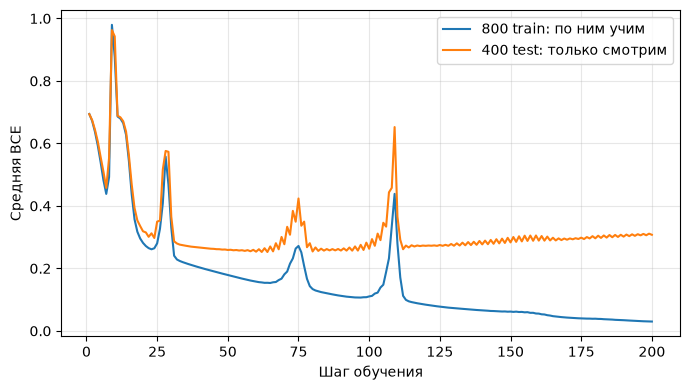

Наименьшая test-потеря: 0.2525 на шаге 64


In [10]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, 201), history, label="800 train: по ним учим")
plt.plot(range(1, 201), test_history, label="400 test: только смотрим")
plt.xlabel("Шаг обучения")
plt.ylabel("Средняя BCE")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
best_step = test_history.index(min(test_history)) + 1
print("Наименьшая test-потеря:", round(min(test_history), 4), "на шаге", best_step)


## C11 · Ошибки на новых рисунках

Теперь веса фиксированы: нужны ответы, а производные для обновления не нужны, поэтому используем torch.no_grad(). p означает оценку чайника, 1-p кота. Выбранный порог p>=0.5 равносилен z>=0, поскольку сигмоида возрастает и sigmoid(0)=0.5. Выберите чайник при z>=0, сравните с меткой, отдельно суммируйте ошибки train/test и разделите каждую сумму на число рисунков своей выборки.

In [11]:
with torch.no_grad():
    train_answers = (model(X_train) >= 0).int()
    test_answers = (model(X_test) >= 0).int()
train_errors = int((train_answers != y_train).sum())
test_errors = int((test_answers != y_test).sum())
print("train:", train_errors, "/", len(y_train))
print("test:", test_errors, "/", len(y_test))
print("test error:", test_errors / len(y_test))


train: 0 / 800
test: 45 / 400
test error: 0.1125


## C12 · На чём сеть ошиблась

Средняя ошибка не показывает, на каких рисунках сеть ошибается. Найдите позиции несовпадений test_answers и y_test, возьмите первые 6 по порядку (не подбирая удачные случаи), восстановите каждую строку как 28x28 и подпишите «метка / ответ». Так можно увидеть конкретные ошибки, но причину отдельной ошибки ещё надо проверять дополнительным опытом.

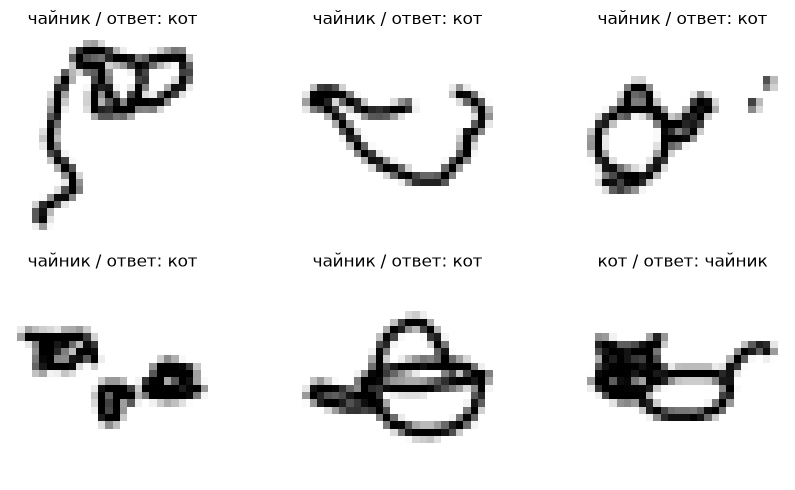

In [12]:
mistakes = torch.where((test_answers != y_test).flatten())[0]
plt.figure(figsize=(9, 5))
for position, index in enumerate(mistakes[:6]):
    plt.subplot(2, 3, position + 1)
    plt.imshow(X_test[index].reshape(28, 28), cmap="gray_r")
    actual = names[int(y_test[index].item())]
    predicted = names[int(test_answers[index].item())]
    plt.title(actual + " / ответ: " + predicted)
    plt.axis("off")
plt.tight_layout()
plt.show()


## C13 · А была ли нужна ReLU?

Проверим, что дал скрытый слой. Обучите модель без него: Linear(784,1) сразу превращает пиксели в z. Всё остальное как у сети: генератор 7, та же потеря, SGD с шагом 0.5, 200 шагов на тех же 800 train-рисунках. Посчитайте ошибки на train и test и напечатайте их рядом с результатом сети.

In [13]:
torch.manual_seed(7)
linear = nn.Linear(784, 1)
linear_optimizer = torch.optim.SGD(linear.parameters(), lr=0.5)
for step in range(200):
    linear_optimizer.zero_grad()
    linear_loss = loss_function(linear(X_train), y_train)
    linear_loss.backward()
    linear_optimizer.step()
with torch.no_grad():
    linear_train = int(((linear(X_train) >= 0).int() != y_train).sum())
    linear_test = int(((linear(X_test) >= 0).int() != y_test).sum())
print("Без скрытого слоя:  train", linear_train, "/ 800, test", linear_test, "/ 400")
print("16 нейронов с ReLU: train", train_errors, "/ 800, test", test_errors, "/ 400")


Без скрытого слоя:  train 29 / 800, test 47 / 400
16 нейронов с ReLU: train 0 / 800, test 45 / 400


## C14 · Рентген: что видит каждый слой

Разберём один test-рисунок по слоям. Первый слой даёт 16 значений hidden после ReLU. Выходной слой умножает каждое на свой вес: получаем 16 «голосов», плюс тянет к чайнику, минус к коту. z равно сумме голосов плюс смещение. Покажите сам рисунок и веса 16 нейронов как картинки 28x28: красный там, где штрих увеличивает сумму нейрона, синий там, где уменьшает. Над каждой картинкой подпишите голос нейрона.

Метка: чайник | p(чайник) = 0.999


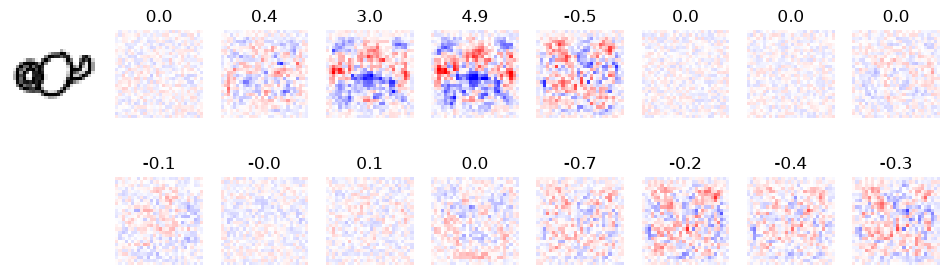

In [14]:
picture = X_test[0]
with torch.no_grad():
    hidden = torch.relu(model[0](picture))
    votes = hidden * model[2].weight[0]
    z = votes.sum() + model[2].bias[0]
print("Метка:", names[int(y_test[0].item())], "| p(чайник) =", round(torch.sigmoid(z).item(), 3))
plt.figure(figsize=(12, 3.5))
plt.subplot(2, 9, 1)
plt.imshow(picture.reshape(28, 28), cmap="gray_r")
plt.axis("off")
for i in range(16):
    plt.subplot(2, 9, i + 2 + i // 8)
    plt.imshow(model[0].weight[i].detach().reshape(28, 28), cmap="bwr", vmin=-0.25, vmax=0.25)
    plt.title(round(votes[i].item(), 1))
    plt.axis("off")
plt.show()


## C15 · Гость из другого класса

Проверим предел списка ответов. В сети только кот и чайник, а rabbit из файла не входил в обучение и test. Покажите этот рисунок, поделите пиксели на ту же шкалу 255, оформите одну строку из 784 входов и без производных получите sigmoid(model(...)). Это оценка чайника в заданной бинарной задаче. Посмотрите, умеет ли модель сообщить «неизвестный предмет», если такой ответ при обучении не задан.

Оценка чайника: 0.777


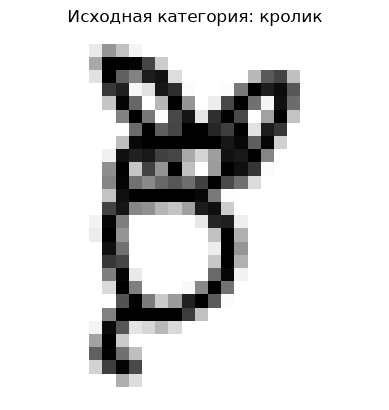

In [15]:
rabbit = torch.tensor(data["rabbit"] / 255.0, dtype=torch.float32).reshape(1, 784)
with torch.no_grad():
    teapot_score = torch.sigmoid(model(rabbit)).item()
print("Оценка чайника:", round(teapot_score, 3))
plt.imshow(rabbit.reshape(28, 28), cmap="gray_r")
plt.title("Исходная категория: кролик")
plt.axis("off")
plt.show()
